<a href="https://colab.research.google.com/github/kandhicharanyadav/Quantum_Computing/blob/main/Product_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
!pip install qiskit==2.4.2 qiskit-aer==0.17.2 matplotlib pylatexenc numpy

In [7]:
import sys
import qiskit
import qiskit_aer

print("Python:", sys.version)
print("Qiskit:", qiskit.__version__)
print("Qiskit Aer:", qiskit_aer.__version__)

Python: 3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]
Qiskit: 2.4.2
Qiskit Aer: 0.17.2


In [10]:
import argparse
import math
from pathlib import Path
from typing import Callable

import matplotlib.pyplot as plt
import numpy as np

from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import QFTGate
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

SIMULATOR = AerSimulator()


def validate_bits(bits: str, name: str = "bit string") -> str:
    bits = bits.replace(" ", "")

    if not bits or set(bits) - {"0", "1"}:
        raise ValueError(f"{name} must contain only 0 and 1.")

    return bits


def simulate_counts(
    circuit: QuantumCircuit,
    shots: int = 2048,
    seed: int = 42
) -> dict[str, int]:

    compiled = transpile(
        circuit,
        SIMULATOR,
        optimization_level=1
    )

    job = SIMULATOR.run(
        compiled,
        shots=shots,
        seed_simulator=seed
    )

    return job.result().get_counts(compiled)


def most_likely(counts: dict[str, int]) -> str:
    return max(counts, key=counts.get)


def save_artifacts(
    circuit: QuantumCircuit,
    counts: dict[str, int],
    stem: str,
    output_dir: str | Path = "outputs"
):

    folder = Path(output_dir)
    folder.mkdir(parents=True, exist_ok=True)

    circuit_path = folder / f"{stem}_circuit.png"
    histogram_path = folder / f"{stem}_histogram.png"

    circuit_figure = circuit.draw(
        output="mpl",
        fold=-1,
        idle_wires=True
    )

    circuit_figure.savefig(
        circuit_path,
        dpi=180,
        bbox_inches="tight"
    )

    plt.close(circuit_figure)

    histogram_figure = plot_histogram(
        counts,
        title=f"{stem}: measurement counts"
    )

    histogram_figure.savefig(
        histogram_path,
        dpi=180,
        bbox_inches="tight"
    )

    plt.close(histogram_figure)

    return circuit_path, histogram_path

In [11]:
def deutsch_jozsa_circuit(
    n: int,
    oracle_type: str = "balanced",
    mask: str | None = None,
    constant_bit: int = 0
) -> QuantumCircuit:

    if n < 1:
        raise ValueError("n must be at least 1.")

    if oracle_type not in {"constant", "balanced"}:
        raise ValueError(
            "oracle_type must be 'constant' or 'balanced'."
        )

    qc = QuantumCircuit(
        n + 1,
        n,
        name="Deutsch-Jozsa"
    )

    output = n

    # Prepare ancilla |1>
    qc.x(output)

    # Apply Hadamard
    qc.h(range(n + 1))

    qc.barrier(label="oracle")

    if oracle_type == "constant":

        if constant_bit not in {0, 1}:
            raise ValueError(
                "constant_bit must be 0 or 1."
            )

        if constant_bit == 1:
            qc.x(output)

    else:

        mask = validate_bits(
            mask or ("1" * n),
            "mask"
        )

        if len(mask) != n or int(mask, 2) == 0:
            raise ValueError(
                "A balanced parity mask must be n bits and nonzero."
            )

        for qubit, bit in enumerate(reversed(mask)):

            if bit == "1":
                qc.cx(qubit, output)

    qc.barrier(label="interfere")

    qc.h(range(n))

    qc.measure(
        range(n),
        range(n)
    )

    return qc


def run_deutsch_jozsa(
    n: int = 4,
    oracle_type: str = "balanced",
    mask: str | None = "1011",
    shots: int = 2048
) -> dict:

    qc = deutsch_jozsa_circuit(
        n,
        oracle_type,
        mask
    )

    counts = simulate_counts(
        qc,
        shots
    )

    observed = most_likely(counts)

    decision = (
        "constant"
        if observed == ("0" * n)
        else "balanced"
    )

    classical_worst = (
        2 ** (n - 1)
    ) + 1

    return {
        "algorithm": "Deutsch-Jozsa",
        "decision": decision,
        "counts": counts,
        "circuit": qc,
        "quantum_queries": 1,
        "classical_deterministic_worst_queries":
            classical_worst
    }

Constant 0
{'0000': 2048}


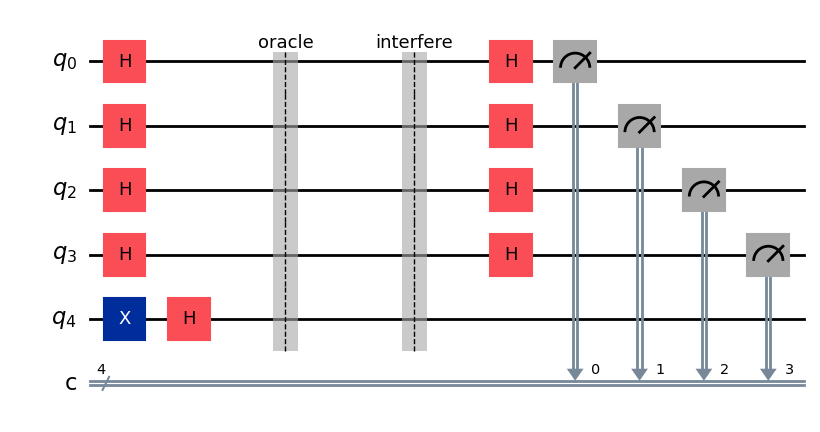

In [12]:
qc = deutsch_jozsa_circuit(
    n=4,
    oracle_type="constant",
    constant_bit=0
)

counts = simulate_counts(
    qc,
    shots=2048
)

print("Constant 0")
print(counts)

qc.draw(output="mpl", fold=-1)

In [13]:
plot_histogram(
    counts,
    title="Deutsch-Jozsa - Constant 0"
)
plt.show()

Constant 1
{'0000': 2048}


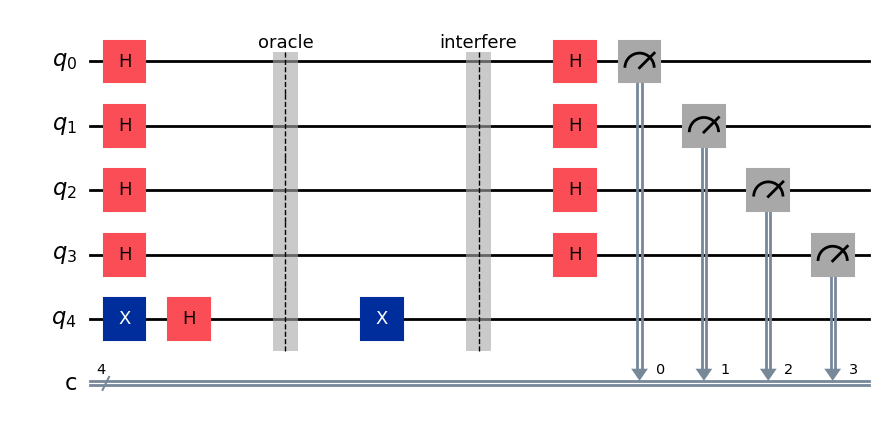

In [14]:
qc = deutsch_jozsa_circuit(
    n=4,
    oracle_type="constant",
    constant_bit=1
)

counts = simulate_counts(
    qc,
    shots=2048
)

print("Constant 1")
print(counts)

qc.draw(output="mpl", fold=-1)

Constant 1
{'0000': 2048}


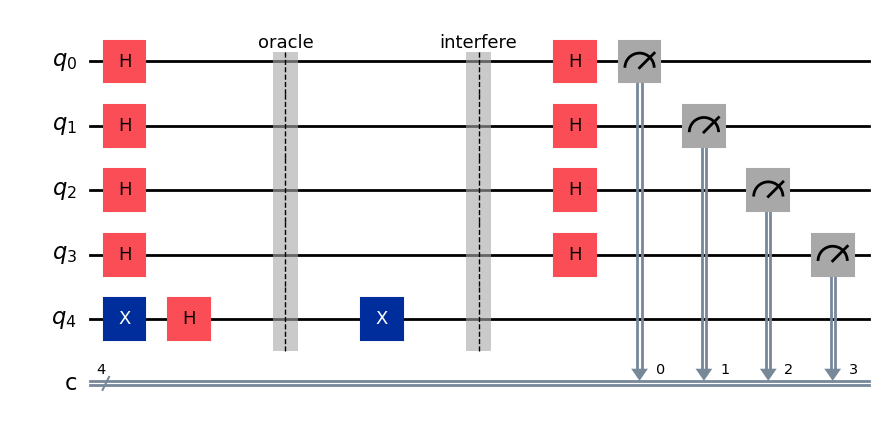

In [15]:
qc = deutsch_jozsa_circuit(
    n=4,
    oracle_type="constant",
    constant_bit=1
)

counts = simulate_counts(
    qc,
    shots=2048
)

print("Constant 1")
print(counts)

qc.draw(output="mpl", fold=-1)

balanced
{'1011': 2048}


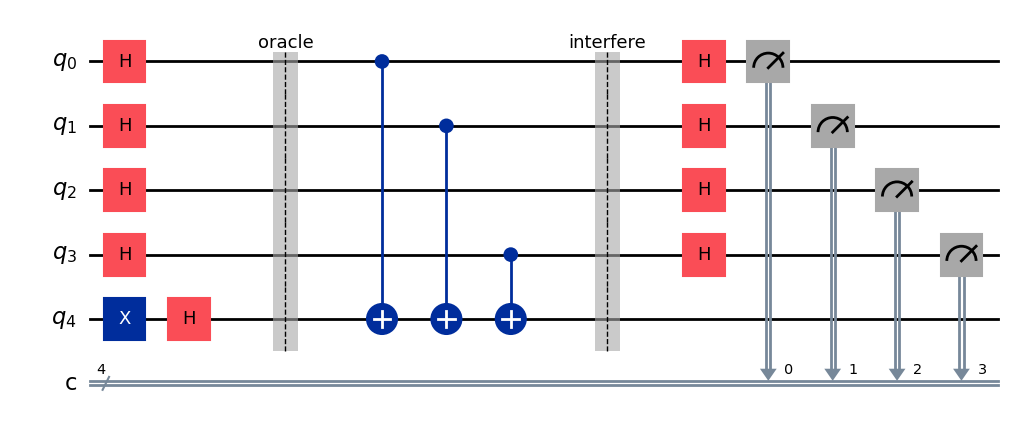

In [16]:
result = run_deutsch_jozsa(
    n=4,
    oracle_type="balanced",
    mask="1011",
    shots=2048
)

print(result["decision"])
print(result["counts"])

result["circuit"].draw(
    output="mpl",
    fold=-1
)

balanced
{'1011': 2048}


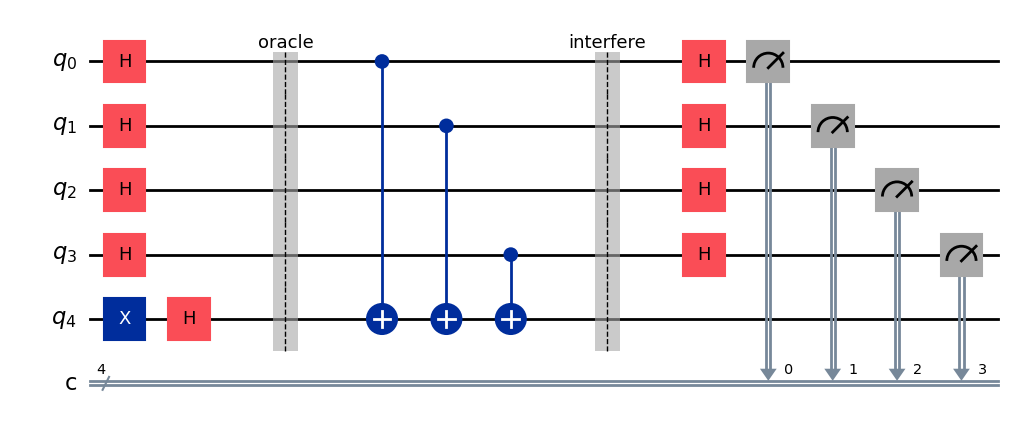

In [17]:
result = run_deutsch_jozsa(
    n=4,
    oracle_type="balanced",
    mask="1011",
    shots=2048
)

print(result["decision"])
print(result["counts"])

result["circuit"].draw(
    output="mpl",
    fold=-1
)

In [18]:
def bernstein_vazirani_circuit(
    secret: str
) -> QuantumCircuit:

    secret = validate_bits(
        secret,
        "secret"
    )

    n = len(secret)

    qc = QuantumCircuit(
        n + 1,
        n,
        name="Bernstein-Vazirani"
    )

    output = n

    # Prepare ancilla
    qc.x(output)

    # Hadamard
    qc.h(range(n + 1))

    qc.barrier(label="oracle")

    # Oracle
    for qubit, bit in enumerate(
        reversed(secret)
    ):

        if bit == "1":
            qc.cx(
                qubit,
                output
            )

    qc.barrier(label="decode")

    # Decode
    qc.h(range(n))

    qc.measure(
        range(n),
        range(n)
    )

    return qc


def run_bernstein_vazirani(
    secret: str = "1011",
    shots: int = 2048
) -> dict:

    qc = bernstein_vazirani_circuit(
        secret
    )

    counts = simulate_counts(
        qc,
        shots
    )

    return {
        "algorithm":
            "Bernstein-Vazirani",

        "secret":
            secret,

        "recovered":
            most_likely(counts),

        "counts":
            counts,

        "circuit":
            qc,

        "quantum_queries":
            1,

        "classical_queries":
            len(secret)
    }

In [19]:
result_bv = run_bernstein_vazirani(
    secret="1011",
    shots=2048
)

print("Algorithm:", result_bv["algorithm"])
print("Secret:", result_bv["secret"])
print("Recovered:", result_bv["recovered"])
print("Counts:", result_bv["counts"])
print("Quantum queries:", result_bv["quantum_queries"])
print("Classical queries:", result_bv["classical_queries"])

Algorithm: Bernstein-Vazirani
Secret: 1011
Recovered: 1011
Counts: {'1011': 2048}
Quantum queries: 1
Classical queries: 4


In [20]:
result_bv = run_bernstein_vazirani(
    secret="1011",
    shots=2048
)

print("Algorithm:", result_bv["algorithm"])
print("Secret:", result_bv["secret"])
print("Recovered:", result_bv["recovered"])
print("Counts:", result_bv["counts"])
print("Quantum queries:", result_bv["quantum_queries"])
print("Classical queries:", result_bv["classical_queries"])

Algorithm: Bernstein-Vazirani
Secret: 1011
Recovered: 1011
Counts: {'1011': 2048}
Quantum queries: 1
Classical queries: 4


In [21]:
plot_histogram(
    result_bv["counts"],
    title="Bernstein-Vazirani"
)
plt.show()

In [22]:
secrets = [
    "101",
    "1011",
    "11010"
]

for secret in secrets:

    result = run_bernstein_vazirani(
        secret=secret,
        shots=2048
    )

    print(
        f"Secret = {secret}, "
        f"Recovered = {result['recovered']}, "
        f"Queries = {result['quantum_queries']}"
    )

Secret = 101, Recovered = 101, Queries = 1
Secret = 1011, Recovered = 1011, Queries = 1
Secret = 11010, Recovered = 11010, Queries = 1


In [23]:
def simon_circuit(
    secret: str
) -> QuantumCircuit:

    secret = validate_bits(
        secret,
        "secret"
    )

    if int(secret, 2) == 0:
        raise ValueError(
            "Simon's nontrivial secret must be nonzero."
        )

    n = len(secret)

    qc = QuantumCircuit(
        2 * n,
        n,
        name="Simon"
    )

    # First register superposition
    qc.h(range(n))

    qc.barrier(
        label="two-to-one oracle"
    )

    # Copy x to output register
    for i in range(n):
        qc.cx(
            i,
            n + i
        )

    # Compute f(x) = x XOR x_p*s
    little_endian_secret = list(
        reversed(secret)
    )

    pivot = little_endian_secret.index("1")

    for i, bit in enumerate(
        little_endian_secret
    ):

        if bit == "1":
            qc.cx(
                pivot,
                n + i
            )

    qc.barrier(
        label="sample y"
    )

    # Hadamard again
    qc.h(range(n))

    qc.measure(
        range(n),
        range(n)
    )

    return qc


def gf2_dot(
    left: str,
    right: str
) -> int:

    return sum(
        int(a) * int(b)
        for a, b in zip(left, right)
    ) % 2


def recover_simon_candidates(
    counts: dict[str, int],
    n: int
) -> list[str]:

    equations = [
        key.replace(" ", "")
        for key in counts
    ]

    return [
        f"{value:0{n}b}"
        for value in range(
            1,
            2 ** n
        )
        if all(
            gf2_dot(
                y,
                f"{value:0{n}b}"
            ) == 0
            for y in equations
        )
    ]


def run_simon(
    secret: str = "110",
    shots: int = 4096
) -> dict:

    qc = simon_circuit(secret)

    counts = simulate_counts(
        qc,
        shots
    )

    candidates = recover_simon_candidates(
        counts,
        len(secret)
    )

    return {
        "algorithm": "Simon",
        "secret": secret,
        "recovered_candidates": candidates,
        "counts": counts,
        "circuit": qc,
        "quantum_queries":
            f"O({len(secret)})",
        "classical_queries":
            f"Theta(2^({len(secret)}/2)) expected"
    }

In [24]:
result_simon = run_simon(
    secret="110",
    shots=4096
)

print("Secret:", result_simon["secret"])
print(
    "Candidates:",
    result_simon["recovered_candidates"]
)
print("Counts:", result_simon["counts"])

Secret: 110
Candidates: ['110']
Counts: {'111': 1037, '000': 993, '001': 1039, '110': 1027}


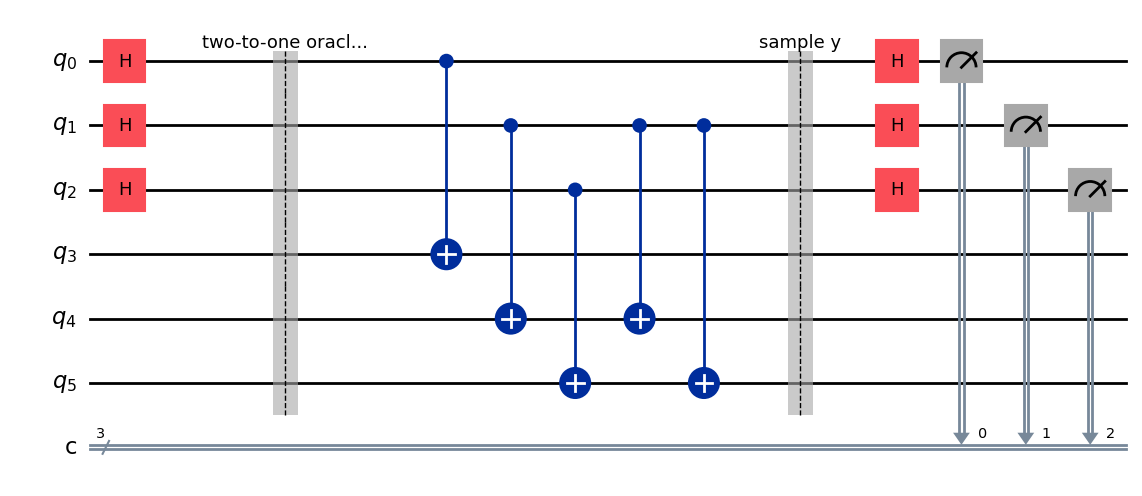

In [25]:
result_simon["circuit"].draw(
    output="mpl",
    fold=-1
)

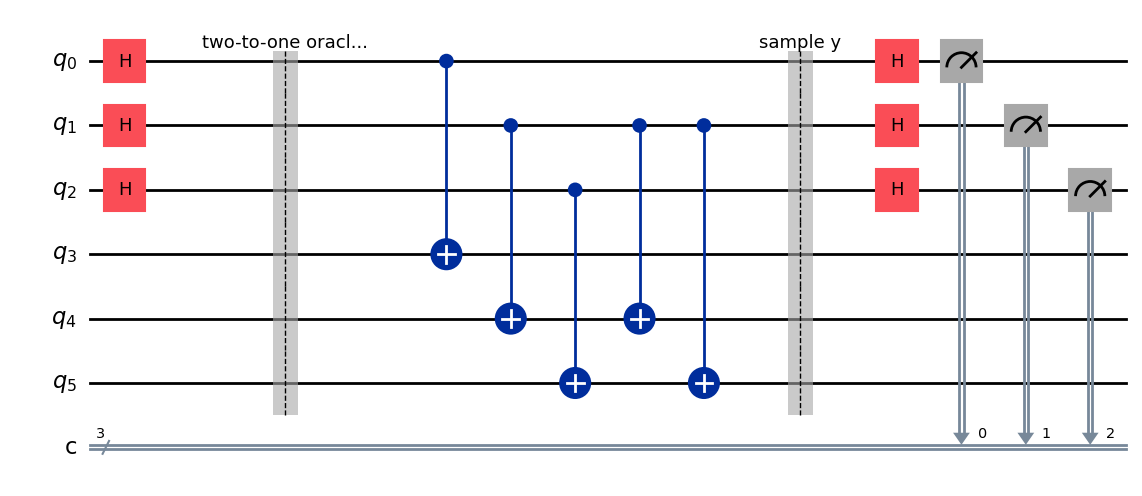

In [26]:
result_simon["circuit"].draw(
    output="mpl",
    fold=-1
)

In [27]:
secret = "110"

counts = result_simon["counts"]

print("Simon equations:")
print()

for y in sorted(counts):

    value = gf2_dot(
        y,
        secret
    )

    print(
        f"y = {y}, "
        f"s = {secret}, "
        f"y.s mod 2 = {value}"
    )

Simon equations:

y = 000, s = 110, y.s mod 2 = 0
y = 001, s = 110, y.s mod 2 = 0
y = 110, s = 110, y.s mod 2 = 0
y = 111, s = 110, y.s mod 2 = 0


In [28]:
result_simon2 = run_simon(
    secret="101",
    shots=4096
)

print("Secret:", result_simon2["secret"])
print(
    "Candidates:",
    result_simon2["recovered_candidates"]
)
print("Counts:", result_simon2["counts"])

Secret: 101
Candidates: ['101']
Counts: {'111': 1037, '101': 1039, '000': 993, '010': 1027}


In [29]:
def apply_phase_mark(
    qc: QuantumCircuit,
    marked: str
) -> None:

    little_endian = list(
        reversed(marked)
    )

    for qubit, bit in enumerate(
        little_endian
    ):

        if bit == "0":
            qc.x(qubit)

    target = len(marked) - 1

    qc.h(target)

    if len(marked) == 1:
        qc.x(target)
    else:
        qc.mcx(
            list(range(target)),
            target
        )

    qc.h(target)

    for qubit, bit in enumerate(
        little_endian
    ):

        if bit == "0":
            qc.x(qubit)


def apply_diffuser(
    qc: QuantumCircuit,
    n: int
) -> None:

    qc.h(range(n))
    qc.x(range(n))

    target = n - 1

    qc.h(target)

    if n == 1:
        qc.x(target)
    else:
        qc.mcx(
            list(range(target)),
            target
        )

    qc.h(target)

    qc.x(range(n))
    qc.h(range(n))


def grover_circuit(
    marked: str,
    iterations: int | None = None
) -> QuantumCircuit:

    marked = validate_bits(
        marked,
        "marked state"
    )

    n = len(marked)

    if iterations is None:

        iterations = max(
            1,
            math.floor(
                (math.pi / 4)
                * math.sqrt(2 ** n)
            )
        )

    qc = QuantumCircuit(
        n,
        n,
        name="Grover"
    )

    # Initial superposition
    qc.h(range(n))

    for _ in range(iterations):

        qc.barrier(
            label="oracle"
        )

        apply_phase_mark(
            qc,
            marked
        )

        qc.barrier(
            label="diffuser"
        )

        apply_diffuser(
            qc,
            n
        )

    qc.measure(
        range(n),
        range(n)
    )

    return qc


def run_grover(
    marked: str = "101",
    shots: int = 4096
) -> dict:

    n = len(
        validate_bits(
            marked,
            "marked state"
        )
    )

    iterations = max(
        1,
        math.floor(
            (math.pi / 4)
            * math.sqrt(2 ** n)
        )
    )

    qc = grover_circuit(
        marked,
        iterations
    )

    counts = simulate_counts(
        qc,
        shots
    )

    success_probability = (
        counts.get(marked, 0)
        / shots
    )

    return {
        "algorithm": "Grover",
        "marked": marked,
        "recovered":
            most_likely(counts),
        "iterations":
            iterations,
        "success_probability":
            success_probability,
        "counts":
            counts,
        "circuit":
            qc,
        "quantum_queries":
            f"O(sqrt(2^{n}))",
        "classical_queries":
            f"O(2^{n})"
    }

In [30]:
def apply_phase_mark(
    qc: QuantumCircuit,
    marked: str
) -> None:

    little_endian = list(
        reversed(marked)
    )

    for qubit, bit in enumerate(
        little_endian
    ):

        if bit == "0":
            qc.x(qubit)

    target = len(marked) - 1

    qc.h(target)

    if len(marked) == 1:
        qc.x(target)
    else:
        qc.mcx(
            list(range(target)),
            target
        )

    qc.h(target)

    for qubit, bit in enumerate(
        little_endian
    ):

        if bit == "0":
            qc.x(qubit)


def apply_diffuser(
    qc: QuantumCircuit,
    n: int
) -> None:

    qc.h(range(n))
    qc.x(range(n))

    target = n - 1

    qc.h(target)

    if n == 1:
        qc.x(target)
    else:
        qc.mcx(
            list(range(target)),
            target
        )

    qc.h(target)

    qc.x(range(n))
    qc.h(range(n))


def grover_circuit(
    marked: str,
    iterations: int | None = None
) -> QuantumCircuit:

    marked = validate_bits(
        marked,
        "marked state"
    )

    n = len(marked)

    if iterations is None:

        iterations = max(
            1,
            math.floor(
                (math.pi / 4)
                * math.sqrt(2 ** n)
            )
        )

    qc = QuantumCircuit(
        n,
        n,
        name="Grover"
    )

    # Initial superposition
    qc.h(range(n))

    for _ in range(iterations):

        qc.barrier(
            label="oracle"
        )

        apply_phase_mark(
            qc,
            marked
        )

        qc.barrier(
            label="diffuser"
        )

        apply_diffuser(
            qc,
            n
        )

    qc.measure(
        range(n),
        range(n)
    )

    return qc


def run_grover(
    marked: str = "101",
    shots: int = 4096
) -> dict:

    n = len(
        validate_bits(
            marked,
            "marked state"
        )
    )

    iterations = max(
        1,
        math.floor(
            (math.pi / 4)
            * math.sqrt(2 ** n)
        )
    )

    qc = grover_circuit(
        marked,
        iterations
    )

    counts = simulate_counts(
        qc,
        shots
    )

    success_probability = (
        counts.get(marked, 0)
        / shots
    )

    return {
        "algorithm": "Grover",
        "marked": marked,
        "recovered":
            most_likely(counts),
        "iterations":
            iterations,
        "success_probability":
            success_probability,
        "counts":
            counts,
        "circuit":
            qc,
        "quantum_queries":
            f"O(sqrt(2^{n}))",
        "classical_queries":
            f"O(2^{n})"
    }

In [31]:
result_grover = run_grover(
    marked="101",
    shots=4096
)

print("Marked state:", result_grover["marked"])
print("Recovered:", result_grover["recovered"])
print("Iterations:", result_grover["iterations"])
print(
    "Success probability:",
    result_grover["success_probability"]
)
print("Counts:", result_grover["counts"])

Marked state: 101
Recovered: 101
Iterations: 2
Success probability: 0.949462890625
Counts: {'100': 21, '111': 31, '011': 30, '110': 41, '000': 33, '010': 26, '001': 25, '101': 3889}


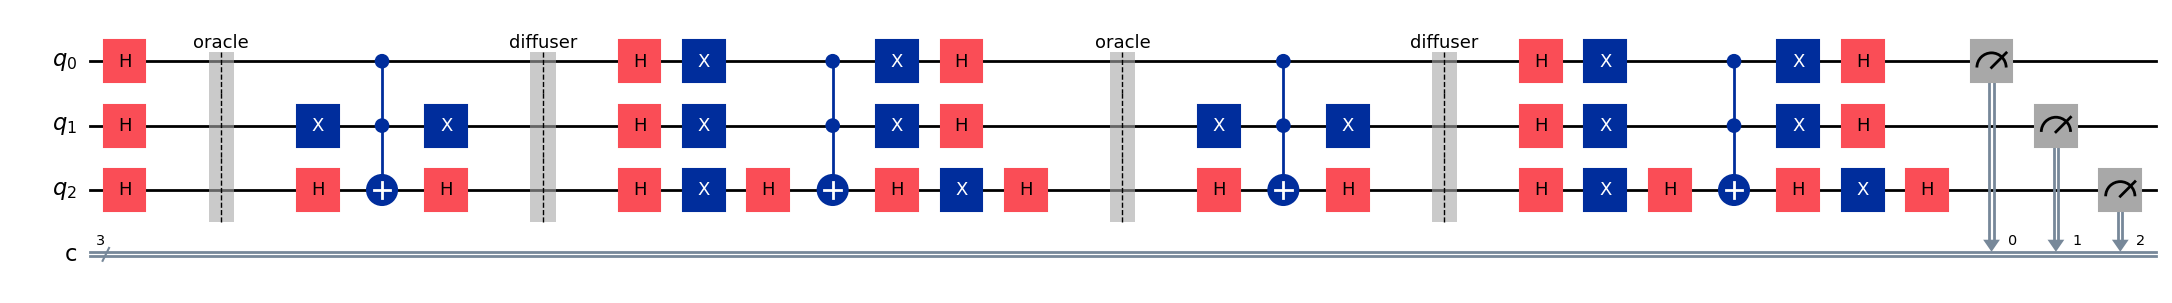

In [32]:
result_grover["circuit"].draw(
    output="mpl",
    fold=-1
)

In [33]:
plot_histogram(
    result_grover["counts"],
    title="Grover Search"
)
plt.show()

In [34]:
targets = [
    "001",
    "101",
    "110"
]

for target in targets:

    result = run_grover(
        marked=target,
        shots=4096
    )

    print(
        f"Target = {target}, "
        f"Recovered = {result['recovered']}, "
        f"Success = {result['success_probability']:.4f}"
    )

Target = 001, Recovered = 001, Success = 0.9473
Target = 101, Recovered = 101, Success = 0.9495
Target = 110, Recovered = 110, Success = 0.9495


In [35]:
marked = "101"
shots = 4096

results = []

for iterations in [1, 2, 3]:

    qc = grover_circuit(
        marked,
        iterations
    )

    counts = simulate_counts(
        qc,
        shots
    )

    success = (
        counts.get(marked, 0)
        / shots
    )

    results.append(
        (iterations, success)
    )

    print(
        f"Iterations = {iterations}, "
        f"Success = {success:.4f}"
    )

Iterations = 1, Success = 0.7913
Iterations = 2, Success = 0.9495
Iterations = 3, Success = 0.3416


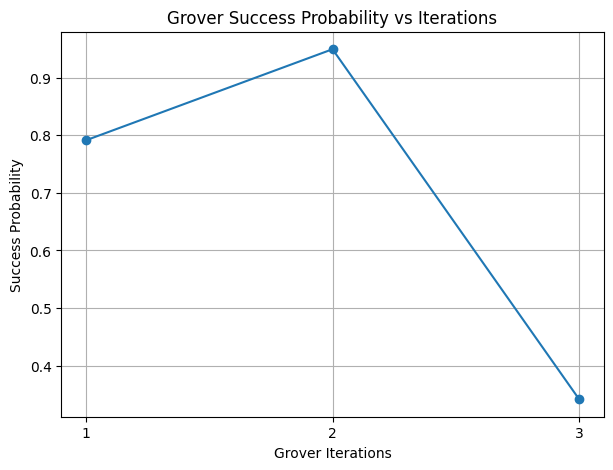

In [36]:
iterations = [
    x[0] for x in results
]

success = [
    x[1] for x in results
]

plt.figure(figsize=(7, 5))

plt.plot(
    iterations,
    success,
    marker="o"
)

plt.xlabel(
    "Grover Iterations"
)

plt.ylabel(
    "Success Probability"
)

plt.title(
    "Grover Success Probability vs Iterations"
)

plt.xticks(iterations)

plt.grid(True)

plt.show()

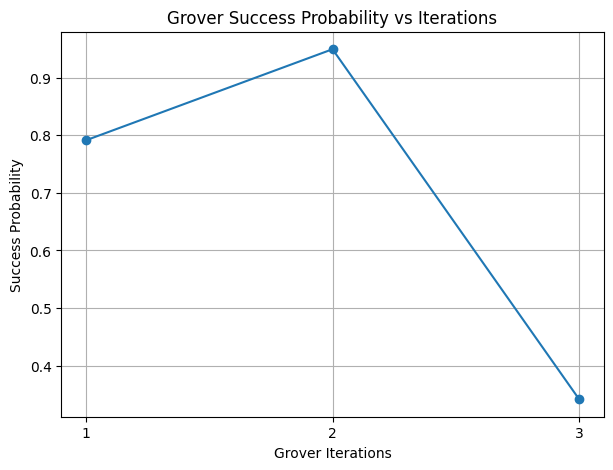

In [37]:
iterations = [
    x[0] for x in results
]

success = [
    x[1] for x in results
]

plt.figure(figsize=(7, 5))

plt.plot(
    iterations,
    success,
    marker="o"
)

plt.xlabel(
    "Grover Iterations"
)

plt.ylabel(
    "Success Probability"
)

plt.title(
    "Grover Success Probability vs Iterations"
)

plt.xticks(iterations)

plt.grid(True)

plt.show()

In [38]:
def qft_round_trip_circuit(
    n: int,
    value: int
) -> QuantumCircuit:

    if n < 1 or not 0 <= value < 2 ** n:
        raise ValueError(
            "Require n >= 1 and 0 <= value < 2**n."
        )

    qc = QuantumCircuit(
        n,
        n,
        name="QFT round trip"
    )

    # Encode |value>
    for qubit in range(n):

        if (value >> qubit) & 1:
            qc.x(qubit)

    qc.barrier(
        label="QFT"
    )

    qc.append(
        QFTGate(n),
        range(n)
    )

    qc.barrier(
        label="inverse QFT"
    )

    qc.append(
        QFTGate(n).inverse(),
        range(n)
    )

    qc.measure(
        range(n),
        range(n)
    )

    return qc


def qft_state(
    n: int,
    value: int
) -> Statevector:

    qc = QuantumCircuit(n)

    for qubit in range(n):

        if (value >> qubit) & 1:
            qc.x(qubit)

    qc.append(
        QFTGate(n),
        range(n)
    )

    return Statevector.from_instruction(qc)


def run_qft(
    n: int = 3,
    value: int = 5,
    shots: int = 2048
) -> dict:

    qc = qft_round_trip_circuit(
        n,
        value
    )

    counts = simulate_counts(
        qc,
        shots
    )

    state = qft_state(
        n,
        value
    )

    phase_degrees = np.angle(
        state.data,
        deg=True
    )

    return {
        "algorithm": "QFT",
        "input_value": value,
        "expected_bits":
            f"{value:0{n}b}",
        "recovered":
            most_likely(counts),
        "counts":
            counts,
        "phase_degrees":
            np.round(
                phase_degrees,
                1
            ).tolist(),
        "circuit":
            qc,
        "quantum_gate_complexity":
            f"O({n}^2)",
        "classical_fft_for_full_vector":
            f"O({n}*2^{n})"
    }

In [41]:
result_qft = run_qft(
    n=3,
    value=5,
    shots=2048
)

print("Input value:", result_qft["input_value"])
print("Expected bits:", result_qft["expected_bits"])
print("Recovered:", result_qft["recovered"])
print("Counts:", result_qft["counts"])
print("Phase degrees:", result_qft["phase_degrees"])

Input value: 5
Expected bits: 101
Recovered: 101
Counts: {'101': 2048}
Phase degrees: [0.0, -135.0, 90.0, -45.0, 180.0, 45.0, -90.0, 135.0]


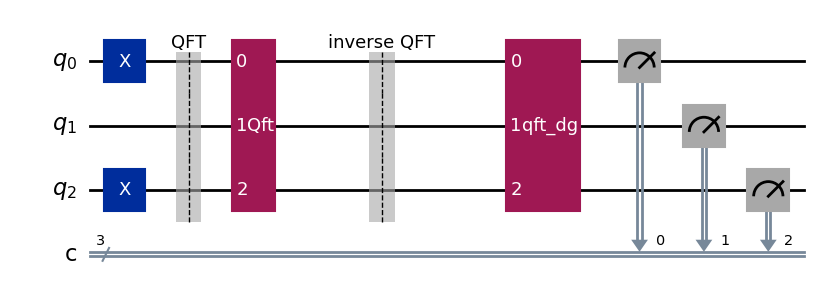

In [42]:
result_qft["circuit"].draw(
    output="mpl",
    fold=-1
)

In [43]:
qft_values = [0, 1, 3, 5]

for value in qft_values:

    result = run_qft(
        n=3,
        value=value,
        shots=2048
    )

    print("=" * 50)
    print("Input:", value)
    print("Binary:", result["expected_bits"])
    print("Recovered:", result["recovered"])
    print("Counts:", result["counts"])
    print("Phases:", result["phase_degrees"])

Input: 0
Binary: 000
Recovered: 000
Counts: {'000': 2048}
Phases: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
Input: 1
Binary: 001
Recovered: 001
Counts: {'001': 2048}
Phases: [0.0, 45.0, 90.0, 135.0, 180.0, -135.0, -90.0, -45.0]
Input: 3
Binary: 011
Recovered: 011
Counts: {'011': 2048}
Phases: [0.0, 135.0, -90.0, 45.0, 180.0, -45.0, 90.0, -135.0]
Input: 5
Binary: 101
Recovered: 101
Counts: {'101': 2048}
Phases: [0.0, -135.0, 90.0, -45.0, 180.0, 45.0, -90.0, 135.0]


In [44]:
value = 5
n = 3

state = qft_state(
    n,
    value
)

probabilities = np.abs(state.data) ** 2

print("QFT probabilities:")

for i, probability in enumerate(probabilities):
    print(
        f"|{i:03b}> : {probability:.4f}"
    )

QFT probabilities:
|000> : 0.1250
|001> : 0.1250
|010> : 0.1250
|011> : 0.1250
|100> : 0.1250
|101> : 0.1250
|110> : 0.1250
|111> : 0.1250


In [45]:
def parity_oracle(
    mask: str,
    constant_bit: int = 0
) -> Callable[[int], int]:

    mask_value = int(
        validate_bits(mask, "mask"),
        2
    )

    return lambda x: (
        ((x & mask_value).bit_count() % 2)
        ^ constant_bit
    )


def classical_deutsch_jozsa(
    n: int,
    oracle: Callable[[int], int]
) -> tuple[str, int]:

    first = oracle(0)
    queries = 1

    for x in range(
        1,
        (2 ** (n - 1)) + 1
    ):

        queries += 1

        if oracle(x) != first:
            return "balanced", queries

    return "constant", queries


def classical_bernstein_vazirani(
    secret: str
) -> tuple[str, int]:

    secret = validate_bits(
        secret,
        "secret"
    )

    n = len(secret)

    oracle = parity_oracle(secret)

    recovered = ["0"] * n

    for qubit in range(n):

        recovered[
            n - 1 - qubit
        ] = str(
            oracle(1 << qubit)
        )

    return "".join(recovered), n


def simon_function(
    x: int,
    secret_value: int,
    n: int
) -> int:

    pivot = (
        secret_value & -secret_value
    ).bit_length() - 1

    return x ^ (
        secret_value
        if ((x >> pivot) & 1)
        else 0
    )


def classical_simon_collision(
    secret: str
) -> tuple[str, int]:

    secret = validate_bits(
        secret,
        "secret"
    )

    n = len(secret)

    secret_value = int(secret, 2)

    seen = {}

    for queries, x in enumerate(
        range(2 ** n),
        start=1
    ):

        fx = simon_function(
            x,
            secret_value,
            n
        )

        if fx in seen:
            return (
                f"{x ^ seen[fx]:0{n}b}",
                queries
            )

        seen[fx] = x

    raise RuntimeError(
        "No collision found."
    )


def classical_linear_search(
    marked: str
) -> tuple[str, int]:

    marked = validate_bits(
        marked,
        "marked state"
    )

    target = int(marked, 2)

    for queries, value in enumerate(
        range(2 ** len(marked)),
        start=1
    ):

        if value == target:
            return (
                f"{value:0{len(marked)}b}",
                queries
            )

    raise RuntimeError(
        "Target not found."
    )


def classical_qft(
    vector: np.ndarray
) -> np.ndarray:

    vector = np.asarray(
        vector,
        dtype=complex
    )

    return (
        np.fft.ifft(vector)
        * math.sqrt(len(vector))
    )

In [46]:
print("QUANTUM ALGORITHM COMPLEXITY COMPARISON")
print("=" * 75)

print("Deutsch-Jozsa     : 1 quantum query")
print("Bernstein-Vazirani: 1 quantum query")
print("Simon             : O(n) quantum queries")
print("Grover            : O(sqrt(N)) quantum queries")
print("QFT               : O(n^2) quantum gates")

print()

print("CLASSICAL BASELINES")
print("=" * 75)

print("Deutsch-Jozsa     : 2^(n-1)+1 worst-case queries")
print("Bernstein-Vazirani: n queries")
print("Simon             : approximately Theta(2^(n/2))")
print("Grover            : O(N) classical search")
print("QFT                : O(n*2^n) for full classical vector")

QUANTUM ALGORITHM COMPLEXITY COMPARISON
Deutsch-Jozsa     : 1 quantum query
Bernstein-Vazirani: 1 quantum query
Simon             : O(n) quantum queries
Grover            : O(sqrt(N)) quantum queries
QFT               : O(n^2) quantum gates

CLASSICAL BASELINES
Deutsch-Jozsa     : 2^(n-1)+1 worst-case queries
Bernstein-Vazirani: n queries
Simon             : approximately Theta(2^(n/2))
Grover            : O(N) classical search
QFT                : O(n*2^n) for full classical vector


In [47]:
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

# Deutsch-Jozsa
dj = run_deutsch_jozsa(
    n=4,
    oracle_type="balanced",
    mask="1011",
    shots=2048
)

save_artifacts(
    dj["circuit"],
    dj["counts"],
    "deutsch_jozsa",
    output_dir
)


# Bernstein-Vazirani
bv = run_bernstein_vazirani(
    "1011",
    2048
)

save_artifacts(
    bv["circuit"],
    bv["counts"],
    "bernstein_vazirani",
    output_dir
)


# Simon
simon = run_simon(
    "110",
    4096
)

save_artifacts(
    simon["circuit"],
    simon["counts"],
    "simon",
    output_dir
)


# Grover
grover = run_grover(
    "101",
    4096
)

save_artifacts(
    grover["circuit"],
    grover["counts"],
    "grover",
    output_dir
)


# QFT
qft = run_qft(
    3,
    5,
    2048
)

save_artifacts(
    qft["circuit"],
    qft["counts"],
    "qft",
    output_dir
)

print("All circuits and histograms saved successfully.")

All circuits and histograms saved successfully.


In [48]:
import os

for root, dirs, files in os.walk("outputs"):
    for file in files:
        print(os.path.join(root, file))

outputs/simon_circuit.png
outputs/bernstein_vazirani_histogram.png
outputs/deutsch_jozsa_histogram.png
outputs/grover_histogram.png
outputs/deutsch_jozsa_circuit.png
outputs/grover_circuit.png
outputs/qft_circuit.png
outputs/simon_histogram.png
outputs/qft_histogram.png
outputs/bernstein_vazirani_circuit.png


In [49]:
print("RUNNING ACCEPTANCE TESTS")
print("=" * 60)

# Deutsch-Jozsa
dj = run_deutsch_jozsa(
    n=4,
    oracle_type="balanced",
    mask="1011",
    shots=2048
)

assert dj["decision"] == "balanced"

print("✓ Deutsch-Jozsa passed")


# Bernstein-Vazirani
bv = run_bernstein_vazirani(
    "1011",
    2048
)

assert bv["recovered"] == "1011"

print("✓ Bernstein-Vazirani passed")


# Simon
simon = run_simon(
    "110",
    4096
)

assert "110" in simon["recovered_candidates"]

for y in simon["counts"]:
    assert gf2_dot(
        y.replace(" ", ""),
        "110"
    ) == 0

print("✓ Simon passed")


# Grover
grover = run_grover(
    "101",
    4096
)

assert grover["recovered"] == "101"

print("✓ Grover passed")


# QFT
qft = run_qft(
    3,
    5,
    2048
)

assert qft["recovered"] == "101"

print("✓ QFT passed")


print()
print("ALL ACCEPTANCE TESTS PASSED!")

RUNNING ACCEPTANCE TESTS
✓ Deutsch-Jozsa passed
✓ Bernstein-Vazirani passed
✓ Simon passed
✓ Grover passed
✓ QFT passed

ALL ACCEPTANCE TESTS PASSED!
